# 10 — Bonus Distribution per Team (current season, 2026/27)

Bonus points (the BPS podium — 3/2/1 per match) are noisy game-by-game but tell a story as the
season builds: *which clubs' assets bank the extra points, and who inside each squad earns
them.* This notebook attributes every bonus point so far to a **team**, then splits each
team's haul **by position** and **by player**.

- **Data:** the official FPL API — `/bootstrap-static/` (name, position, team) and
  `/event/{gw}/live/` (per-player, per-GW `bonus`) for every finished GW plus the in-progress
  one (provisional: bonus is only final once a GW finishes).
- **Question:** by team → by position → by player → by concentration, where does bonus come from?
- Season-to-date, so samples are small early on: read shares with that in mind.

In [1]:
SEASON = "2026-27"          # display label only - the API always serves the current season
API    = "https://fantasy.premierleague.com/api"
BOOTSTRAP_URL = f"{API}/bootstrap-static/"
LIVE_URL      = API + "/event/{gw}/live/"

POS_ORDER = ["GK", "DEF", "MID", "FWD"]
TOP_PLAYERS = 20   # leaderboard length for the by-player view
POOL_PER_MATCH = 6   # 3+2+1 bonus points awarded in every match
FIXTURES_URL = f"{API}/fixtures/"


In [2]:
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def get_json(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return json.load(urllib.request.urlopen(req, timeout=60))

# --- metadata: element id -> name / position / team ---
boot = get_json(BOOTSTRAP_URL)
POS_MAP   = {1: "GK", 2: "DEF", 3: "MID", 4: "FWD"}
team_name = {t["id"]: t["name"] for t in boot["teams"]}
meta = {e["id"]: (e["web_name"],
                  POS_MAP[e["element_type"]], team_name[e["team"]])
        for e in boot["elements"]}

# --- finished GWs + the current in-progress GW (provisional bonus) ---
finished    = [ev["id"] for ev in boot["events"] if ev["finished"]]
in_progress = [ev["id"] for ev in boot["events"]
               if ev.get("is_current") and not ev["finished"]]
to_fetch    = sorted(set(finished) | set(in_progress))

rows = []
for gw_id in to_fetch:
    for el in get_json(LIVE_URL.format(gw=gw_id))["elements"]:
        name, position, team = meta[el["id"]]
        rows.append({"name": name, "team": team, "position": position,
                     "round": gw_id, "bonus": el["stats"]["bonus"],
                     "minutes": el["stats"]["minutes"]})

gw = pd.DataFrame(rows)
prov = f" + GW{in_progress} in progress (provisional)" if in_progress else ""
print(f"{len(gw):,} player-GW rows | {gw['name'].nunique()} players | "
      f"{gw['team'].nunique()} teams | GWs {gw['round'].min()}-{gw['round'].max()} "
      f"({len(finished)} finished{prov})")
print(f"Total bonus points so far: {int(gw['bonus'].sum()):,}")
# --- matches played per team (bonus is only awarded once a match ends) ---
fixtures = get_json(FIXTURES_URL)
matches = pd.Series(0, index=sorted(team_name.values()), name="matches")
for f in fixtures:
    if f["finished"] or f.get("finished_provisional"):
        matches[team_name[f["team_h"]]] += 1
        matches[team_name[f["team_a"]]] += 1
print(f"Matches played per club: {matches.min()}-{matches.max()} "
      f"(pool = {POOL_PER_MATCH} bonus per match)")


5,220 player-GW rows | 649 players | 20 teams | GWs 1-8 (8 finished)
Total bonus points so far: 508
Matches played per club: 8-8 (pool = 6 bonus per match)


## By team — total bonus banked
Raw totals mislead when clubs have played different numbers of matches (postponements, the
in-progress GW), so the headline metric is **bonus per match**. Each match hands out 6 bonus
points shared between both sides, so a neutral club averages **3.0 per match**.

In [3]:
team_total = (gw.groupby("team")["bonus"].sum()
                .reindex(matches.index, fill_value=0).astype(int))
assert team_total.sum() == int(gw["bonus"].sum()), "team split must be lossless"

league = team_total.sum()
team_tbl = pd.DataFrame({"bonus": team_total, "matches": matches})
team_tbl["per_match"] = (team_tbl["bonus"] / team_tbl["matches"]).round(2)
# share of the bonus pool the club's matches handed out (6 per match)
team_tbl["%pool"] = (team_tbl["bonus"] / (team_tbl["matches"] * POOL_PER_MATCH) * 100).round(1)
team_tbl["%league"] = (team_tbl["bonus"] / league * 100).round(1)
team_tbl = team_tbl.sort_values("per_match", ascending=False)
team_tbl


,bonus,matches,per_match,%pool,%league
Arsenal,45,8,5.62,93.8,8.9
Man City,44,8,5.50,91.7,8.7
Brighton,37,8,4.62,77.1,7.3
Liverpool,34,8,4.25,70.8,6.7
Leeds,32,8,4.00,66.7,6.3
Brentford,31,8,3.88,64.6,6.1
Bournemouth,30,8,3.75,62.5,5.9
Aston Villa,28,8,3.50,58.3,5.5
Newcastle,26,8,3.25,54.2,5.1
Everton,24,8,3.00,50.0,4.7


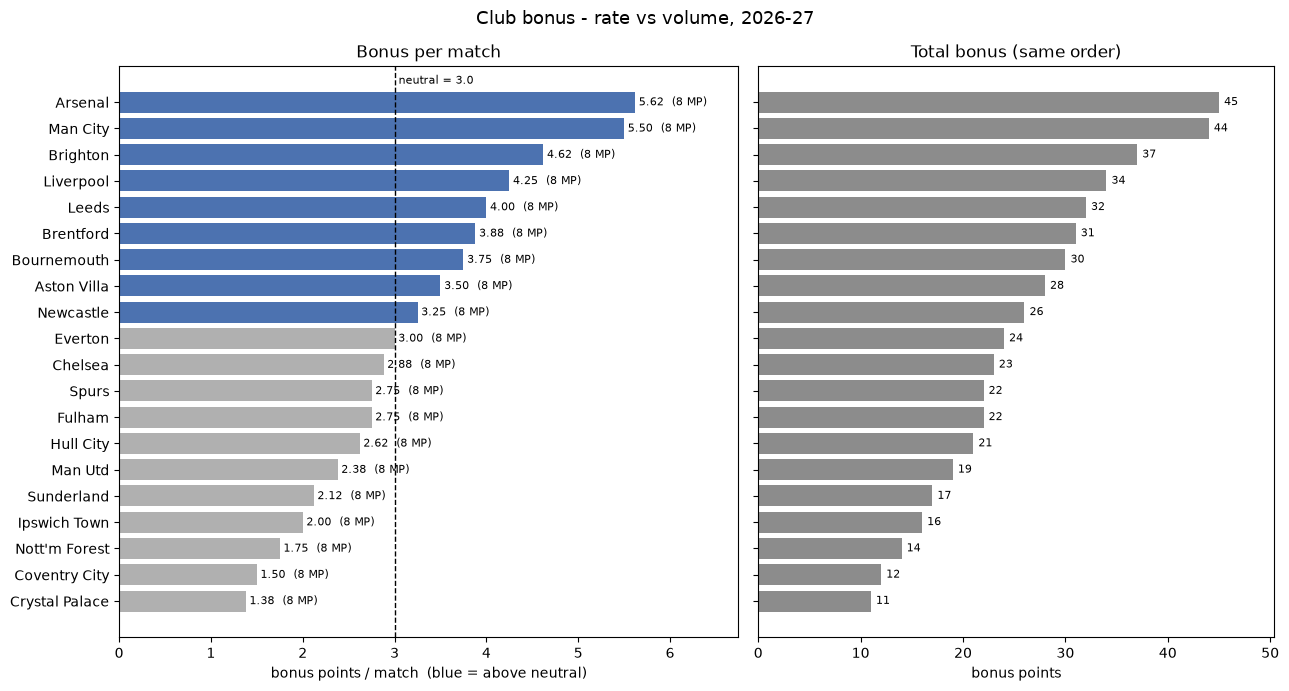

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True,
                         gridspec_kw={"width_ratios": [1.2, 1]})
order = team_tbl.sort_values("per_match")
base = "#4c72b0"
ax = axes[0]
cols = [base if v > 3 else "#b0b0b0" for v in order["per_match"]]
ax.barh(order.index, order["per_match"], color=cols)
ax.axvline(POOL_PER_MATCH / 2, color="k", ls="--", lw=1)
ax.text(POOL_PER_MATCH / 2, len(order) - 0.4, " neutral = 3.0", fontsize=8, va="bottom")
for y, (v, m) in enumerate(zip(order["per_match"], order["matches"])):
    ax.text(v + 0.04, y, f"{v:.2f}  ({m} MP)", va="center", fontsize=8)
ax.set_title("Bonus per match", fontsize=12)
ax.set_xlabel("bonus points / match  (blue = above neutral)")
ax.margins(x=0.2)

ax = axes[1]
ax.barh(order.index, order["bonus"], color="#8c8c8c")
for y, v in enumerate(order["bonus"]):
    ax.text(v + 0.5, y, str(int(v)), va="center", fontsize=8)
ax.set_title("Total bonus (same order)", fontsize=12)
ax.set_xlabel("bonus points")
ax.margins(x=0.12)
fig.suptitle(f"Club bonus - rate vs volume, {SEASON}", fontsize=13)
plt.tight_layout(); plt.show()


## By position — where each club's bonus came from
Same team totals, decomposed into GK / DEF / MID / FWD. The stacked bars show volume; the
heatmap and diverging chart below show each club's position mix against the league average,
which is the real "what kind of club" read (attack-heavy vs defence-led).

In [5]:
team_pos = (gw.pivot_table(index="team", columns="position", values="bonus",
                           aggfunc="sum", fill_value=0)
              .reindex(columns=POS_ORDER, fill_value=0).astype(int))
team_pos["TOTAL"] = team_pos.sum(axis=1)
team_pos = team_pos.sort_values("TOTAL", ascending=False)
team_pos

position,GK,DEF,MID,FWD,TOTAL
team,,,,,
Arsenal,6,17,20,2,45
Man City,1,11,18,14,44
Brighton,2,14,15,6,37
Liverpool,5,7,8,14,34
Leeds,8,13,4,7,32
Brentford,0,5,26,0,31
Bournemouth,0,8,18,4,30
Aston Villa,5,3,13,7,28
Newcastle,1,10,10,5,26


In [6]:
# 100% within-team share — what fraction of each club's bonus each line earned
share = team_pos[POS_ORDER].div(team_pos["TOTAL"], axis=0) * 100
share.round(1)

position,GK,DEF,MID,FWD
team,,,,
Arsenal,13.3,37.8,44.4,4.4
Man City,2.3,25.0,40.9,31.8
Brighton,5.4,37.8,40.5,16.2
Liverpool,14.7,20.6,23.5,41.2
Leeds,25.0,40.6,12.5,21.9
Brentford,0.0,16.1,83.9,0.0
Bournemouth,0.0,26.7,60.0,13.3
Aston Villa,17.9,10.7,46.4,25.0
Newcastle,3.8,38.5,38.5,19.2


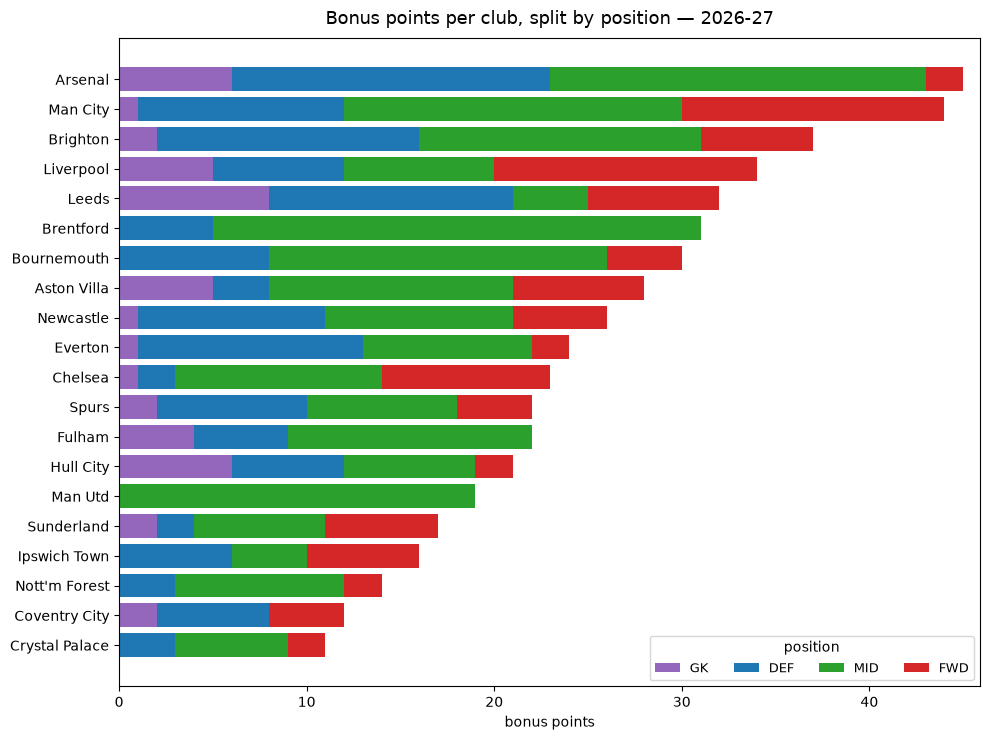

In [7]:
fig, ax = plt.subplots(figsize=(10, 7.5))
order = team_pos.sort_values("TOTAL")           # smallest at bottom
pos_colors = {"GK": "#9467bd", "DEF": "#1f77b4", "MID": "#2ca02c", "FWD": "#d62728"}
left = np.zeros(len(order))
for pos in POS_ORDER:
    vals = order[pos].values
    ax.barh(order.index, vals, left=left, color=pos_colors[pos], label=pos)
    left += vals
ax.set_title(f"Bonus points per club, split by position — {SEASON}", fontsize=13, pad=10)
ax.set_xlabel("bonus points")
ax.legend(title="position", ncol=4, loc="lower right", fontsize=9)
ax.margins(x=0.02)
plt.tight_layout(); plt.show()

In [8]:
# League-wide: which position earns bonus at all?
league_pos = gw.groupby("position")["bonus"].sum().reindex(POS_ORDER).astype(int)
league_pos_pct = (league_pos / league * 100).round(1)
pd.DataFrame({"bonus": league_pos, "%league": league_pos_pct})

,bonus,%league
position,,
GK,46,9.1
DEF,141,27.8
MID,225,44.3
FWD,96,18.9


### Position mix as a heatmap
Each cell is the % of that club's bonus earned by that position line.

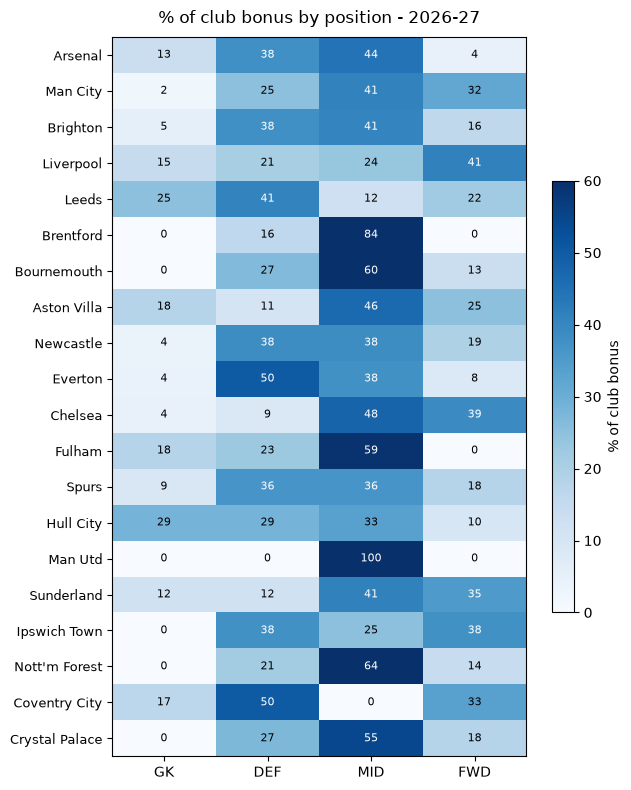

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 8))
hm = share.loc[team_pos.index]
im = ax.imshow(hm.values, cmap="Blues", aspect="auto", vmin=0, vmax=60)
ax.set_xticks(range(4)); ax.set_xticklabels(POS_ORDER)
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index, fontsize=9)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > 35 else "black")
ax.set_title(f"% of club bonus by position - {SEASON}", fontsize=12, pad=10)
plt.colorbar(im, ax=ax, label="% of club bonus", shrink=0.6)
plt.tight_layout(); plt.show()


### Position mix vs the league average
Share minus league share, in percentage points. Positive = the club leans on that line more than the typical club does. Sorted by the largest absolute deviation.

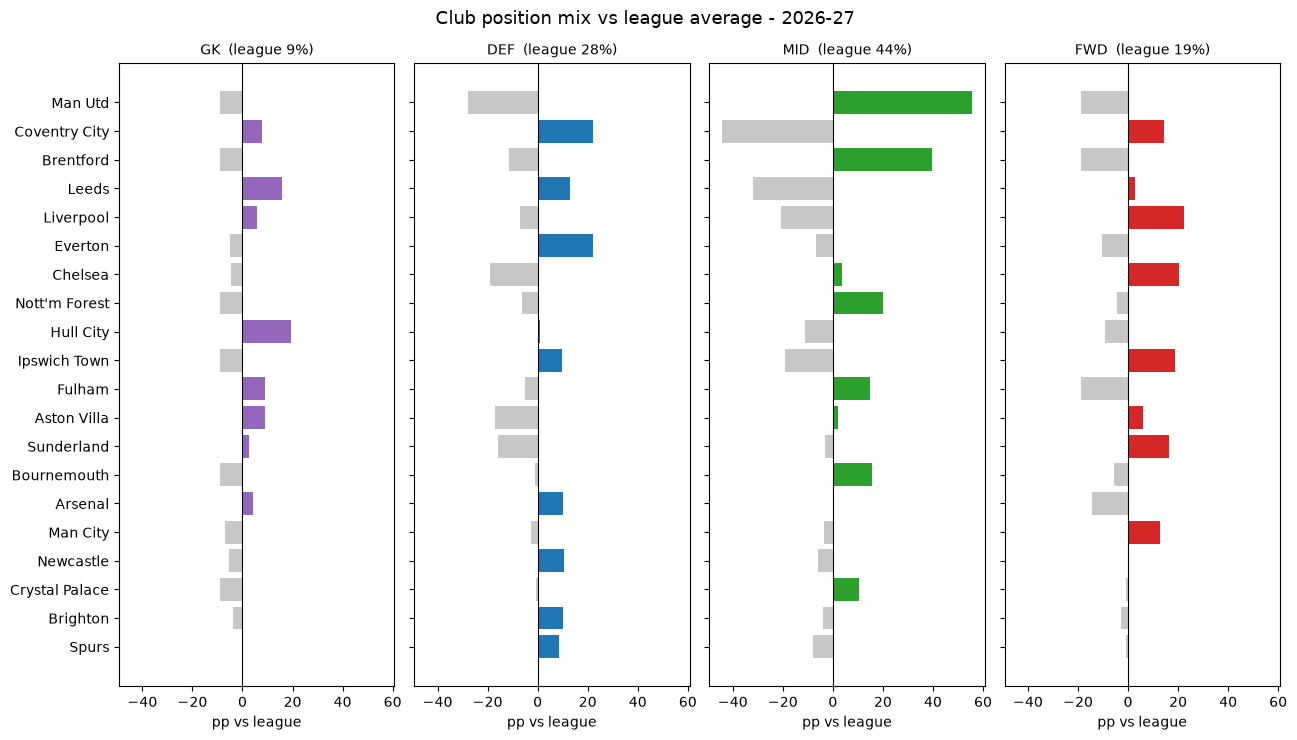

In [10]:
league_share = league_pos / league * 100
diff = share.loc[team_pos.index].sub(league_share, axis=1)
diff = diff.loc[diff.abs().max(axis=1).sort_values().index]   # biggest deviation at top

fig, axes = plt.subplots(1, 4, figsize=(13, 7.5), sharey=True, sharex=True)
for ax, pos in zip(axes, POS_ORDER):
    v = diff[pos]
    ax.barh(diff.index, v, color=[pos_colors[pos] if x > 0 else "#c7c7c7" for x in v])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{pos}  (league {league_share[pos]:.0f}%)", fontsize=10)
    ax.set_xlabel("pp vs league")
fig.suptitle(f"Club position mix vs league average - {SEASON}", fontsize=13)
plt.tight_layout(); plt.show()


## By player — the individual bonus magnets
Who personally banked the bonus. Leaderboard of the top earners, coloured by position, with
their club labelled — the granular layer under the team totals above.

In [11]:
player = (gw.groupby(["name", "team", "position"])["bonus"].sum()
            .reset_index().sort_values("bonus", ascending=False).reset_index(drop=True))
player.head(TOP_PLAYERS)

,name,team,position,bonus
0,Haaland,Man City,FWD,14
1,Isak,Liverpool,FWD,14
2,Tavernier,Bournemouth,MID,12
3,Groß,Brighton,MID,9
4,João Pedro,Chelsea,FWD,9
5,Trafford,Leeds,GK,8
6,De Cuyper,Brighton,DEF,8
7,N.Jackson,Aston Villa,FWD,7
8,Cunha,Man Utd,MID,7
9,Calvert-Lewin,Leeds,FWD,7


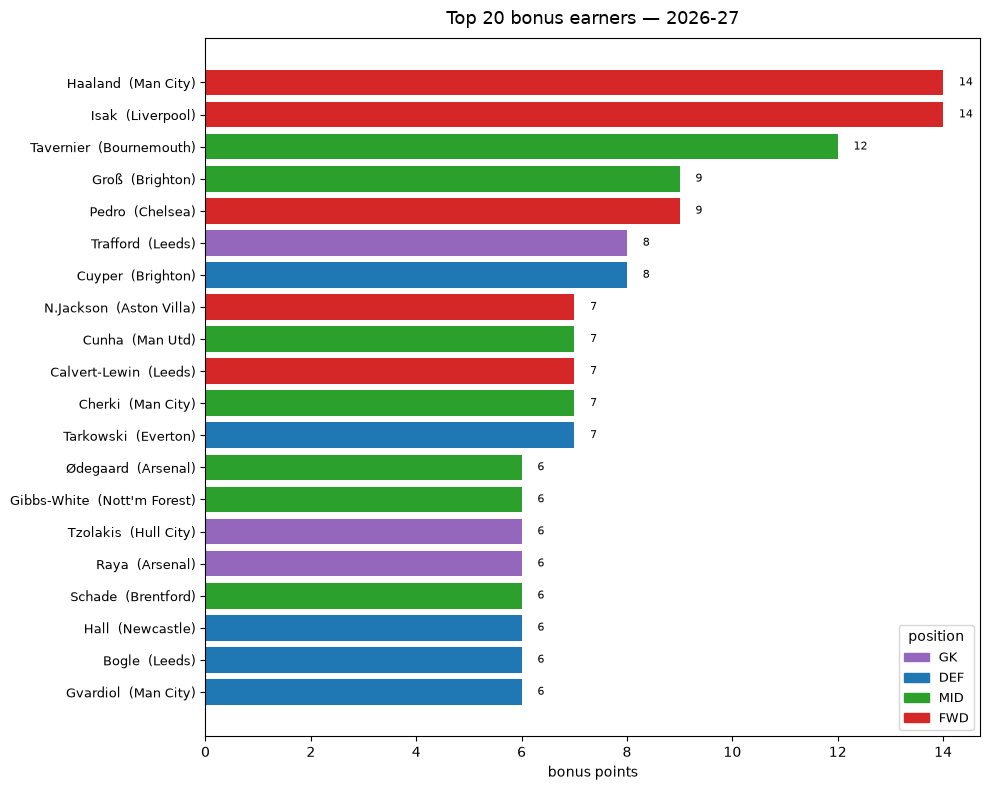

In [12]:
top = player.head(TOP_PLAYERS).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
bar_colors = [pos_colors[p] for p in top["position"]]
labels = [f"{n.split()[-1] if len(n.split())>1 else n}  ({t})"
          for n, t in zip(top["name"], top["team"])]
ax.barh(range(len(top)), top["bonus"], color=bar_colors)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(labels, fontsize=9)
for y, v in enumerate(top["bonus"].values):
    ax.text(v + 0.3, y, str(int(v)), va="center", fontsize=8)
handles = [plt.Rectangle((0,0),1,1,color=pos_colors[p]) for p in POS_ORDER]
ax.legend(handles, POS_ORDER, title="position", loc="lower right", fontsize=9)
ax.set_title(f"Top {TOP_PLAYERS} bonus earners — {SEASON}", fontsize=13, pad=10)
ax.set_xlabel("bonus points")
ax.margins(x=0.05)
plt.tight_layout(); plt.show()

In [13]:
# Each club's single biggest bonus contributor, and how concentrated the haul is
top_per_team = (player.sort_values("bonus", ascending=False)
                      .groupby("team").head(2)
                      .set_index("team")[["name", "position", "bonus"]])
top_per_team = top_per_team.join(team_total.rename("team_total"))
top_per_team["%of_team"] = (top_per_team["bonus"] / top_per_team["team_total"] * 100).round(1)
top_per_team.sort_values("%of_team", ascending=False)

,name,position,bonus,team_total,%of_team
team,,,,,
Nott'm Forest,Gibbs-White,MID,6,14,42.9
Liverpool,Isak,FWD,14,34,41.2
Bournemouth,Tavernier,MID,12,30,40.0
Chelsea,João Pedro,FWD,9,23,39.1
Ipswich Town,Emersonn,FWD,6,16,37.5
Man Utd,Cunha,MID,7,19,36.8
Man City,Haaland,FWD,14,44,31.8
Sunderland,Xhaka,MID,5,17,29.4
Everton,Tarkowski,DEF,7,24,29.2


## By concentration — top-3 players vs the rest
Every club's bonus split into its **three biggest earners** and **everyone else**. This is the
"how reliant is the club on a few names" read: a tall top-3 slice means the haul rests on a
handful of assets, a fat "rest" slice means bonus is spread across the squad.

In [14]:
# Split each club's bonus into its top-3 earners vs the rest
ranked = player.sort_values(["team", "bonus"], ascending=[True, False])
ranked["rank_in_team"] = ranked.groupby("team").cumcount() + 1
ranked["bucket"] = np.where(ranked["rank_in_team"] <= 3, "top3", "rest")

conc = (ranked.groupby(["team", "bucket"])["bonus"].sum()
              .unstack(fill_value=0).reindex(columns=["top3", "rest"], fill_value=0)
              .astype(int))
conc["TOTAL"] = conc.sum(axis=1)
conc["top3_%"] = (conc["top3"] / conc["TOTAL"] * 100).round(1)
conc = conc.sort_values("TOTAL", ascending=False)
assert conc["TOTAL"].sum() == league, "top3/rest split must be lossless"
conc

bucket,top3,rest,TOTAL,top3_%
team,,,,
Arsenal,17,28,45,37.8
Man City,27,17,44,61.4
Brighton,23,14,37,62.2
Liverpool,24,10,34,70.6
Leeds,21,11,32,65.6
Brentford,14,17,31,45.2
Bournemouth,21,9,30,70.0
Aston Villa,17,11,28,60.7
Newcastle,13,13,26,50.0


In [15]:
# The three biggest bonus earners per club, laid out clearly (name + bonus each)
top3 = ranked[ranked["rank_in_team"] <= 3].copy()
top3["slot"] = top3["rank_in_team"].map({1: "1st", 2: "2nd", 3: "3rd"})
top3["cell"] = top3["name"] + " — " + top3["bonus"].astype(str)
top3_tbl = (top3.pivot(index="team", columns="slot", values="cell")
                .reindex(columns=["1st", "2nd", "3rd"]))
top3_tbl = top3_tbl.join(conc[["top3", "TOTAL", "top3_%"]])
top3_tbl = top3_tbl.sort_values("top3_%", ascending=False)
top3_tbl

,1st,2nd,3rd,top3,TOTAL,top3_%
team,,,,,,
Man Utd,Cunha — 7,Mbeumo — 5,B.Fernandes — 3,15,19,78.9
Coventry City,Cherif — 3,Thomas — 3,Dasilva — 3,9,12,75.0
Ipswich Town,Emersonn — 6,O'Shea — 3,Enciso — 3,12,16,75.0
Crystal Palace,Mitchell — 3,Yeremy — 3,Wharton — 2,8,11,72.7
Nott'm Forest,Gibbs-White — 6,Ndoye — 2,Muñoz — 2,10,14,71.4
Liverpool,Isak — 14,A.Becker — 5,Gakpo — 5,24,34,70.6
Bournemouth,Tavernier — 12,Scott — 5,Evanilson — 4,21,30,70.0
Everton,Tarkowski — 7,Dewsbury-Hall — 6,Mykolenko — 3,16,24,66.7
Leeds,Trafford — 8,Calvert-Lewin — 7,Bogle — 6,21,32,65.6


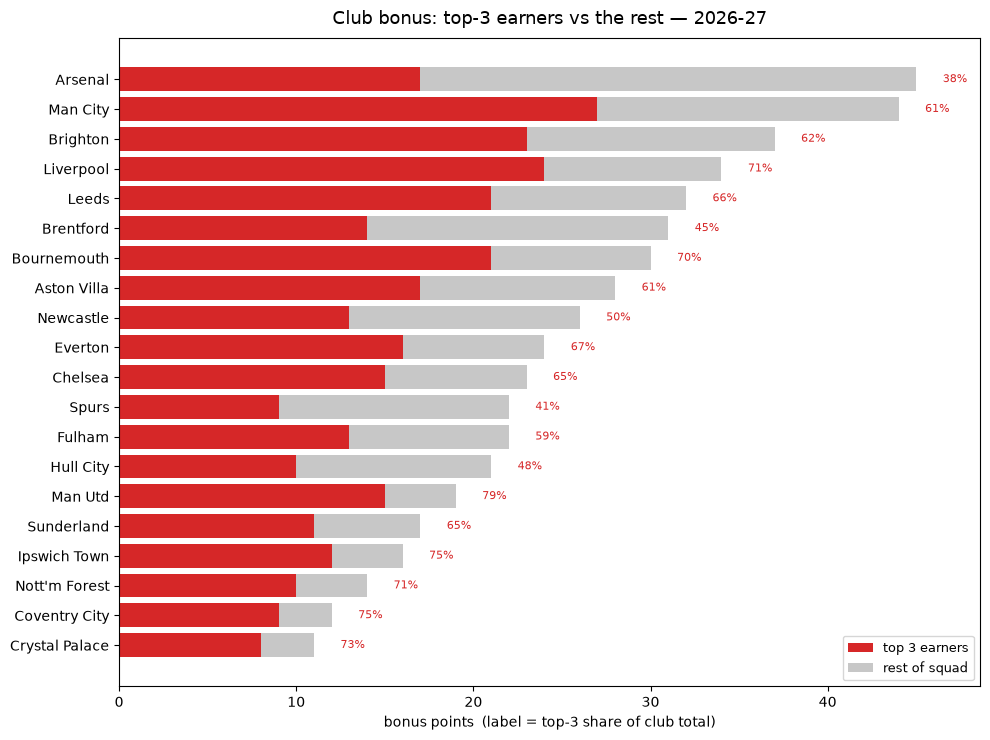

In [16]:
fig, ax = plt.subplots(figsize=(10, 7.5))
order = conc.sort_values("TOTAL")                # smallest at bottom
bucket_colors = {"top3": "#d62728", "rest": "#c7c7c7"}
left = np.zeros(len(order))
for bucket, lbl in [("top3", "top 3 earners"), ("rest", "rest of squad")]:
    vals = order[bucket].values
    ax.barh(order.index, vals, left=left, color=bucket_colors[bucket], label=lbl)
    left += vals
for y, (tot, pct) in enumerate(zip(order["TOTAL"].values, order["top3_%"].values)):
    ax.text(tot + 1.5, y, f"{pct:.0f}%", va="center", fontsize=8, color="#d62728")
ax.set_title(f"Club bonus: top-3 earners vs the rest — {SEASON}", fontsize=13, pad=10)
ax.set_xlabel("bonus points  (label = top-3 share of club total)")
ax.legend(title="", loc="lower right", fontsize=9)
ax.margins(x=0.08)
plt.tight_layout(); plt.show()

## Caveats
- Team label is the player's *current* club per the API; a mid-season mover has all their
  bonus attributed to the new club.
- The in-progress GW's bonus is provisional until that GW finishes.
- Bonus is the raw awarded value — a retrospective of *what happened*, not a BPS prediction.
- Season-to-date sample: few GWs, so rankings will still reshuffle.